In [2]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lightgbm import LGBMRegressor
from scipy.stats import spearmanr

In [3]:
df = pd.read_pickle("../data/processed/fd001_basis_c.pkl")
feature_cols = [c for c in df.columns if c not in ["unit", "RUL"]]

In [4]:
X = df[feature_cols]
y = df["RUL"]

model = LGBMRegressor(verbose = -1, n_jobs = 1, random_state=42)
model.fit(X, y)

,random_state,42
,n_jobs,1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [5]:
explainer = shap.TreeExplainer(model)
shap_werte = explainer.shap_values(X)

In [6]:
shap_werte.shape

(20631, 98)

In [7]:
np.allclose(model.predict(X), (shap_werte.sum(axis=1) + explainer.expected_value))

True

In [8]:
print(explainer.expected_value)
print(y.mean())

86.82928602578225
86.82928602588338


In [9]:
feature_shap = np.abs(shap_werte).mean(axis = 0)
feature_importance = pd.Series(feature_shap, index = feature_cols)
feature_importance.sort_values(ascending=False).head(10)

s4_mean5       7.540240
s15_mean5      3.734426
s11_slope25    3.448518
s11_mean5      2.717997
s12_slope25    2.672856
s9_slope25     2.330824
s8_slope25     2.208033
s2_mean5       2.107821
s14_slope25    2.070767
s13_slope25    1.898039
dtype: float64

In [10]:
sensor_namen = []
typen = []

for col in feature_cols:
    teile = col.split("_", 1)
    sensor_namen.append(teile[0])
    if len(teile)==1:
        name = "roh"
        typen.append(name)
    else:
        typen.append(teile[1])


shap_df = pd.DataFrame({
    "feature": feature_cols,
    "wichtigkeit": feature_importance.to_numpy(),
    "sensor": sensor_namen,
    "typ": typen,
})


shap_df

,feature,wichtigkeit,sensor,typ
0,s2,0.000000,s2,roh
1,s3,0.004061,s3,roh
2,s4,0.001866,s4,roh
3,s8,0.000000,s8,roh
4,s11,0.000000,s11,roh
...,...,...,...,...
93,s12_slope25,2.672856,s12,slope25
94,s20_slope25,1.021076,s20,slope25
95,s21_slope25,1.063290,s21,slope25
96,s9_slope25,2.330824,s9,slope25


In [11]:
shap_df.groupby("typ")["wichtigkeit"].sum().sort_values(ascending=False)

typ
slope25     23.146532
mean5       22.291218
mean25       7.673696
std25        3.144533
diff5_25     0.679464
std5         0.288214
roh          0.094265
Name: wichtigkeit, dtype: float64

In [12]:
shap_df.groupby("sensor")["wichtigkeit"].sum().sort_values(ascending = False)

sensor
s4     9.440385
s11    6.867632
s15    5.456796
s9     5.172837
s14    4.273642
s2     3.872677
s12    3.475552
s8     3.129451
s21    2.750167
s17    2.710189
s7     2.703006
s20    2.601898
s13    2.547243
s3     2.316447
Name: wichtigkeit, dtype: float64

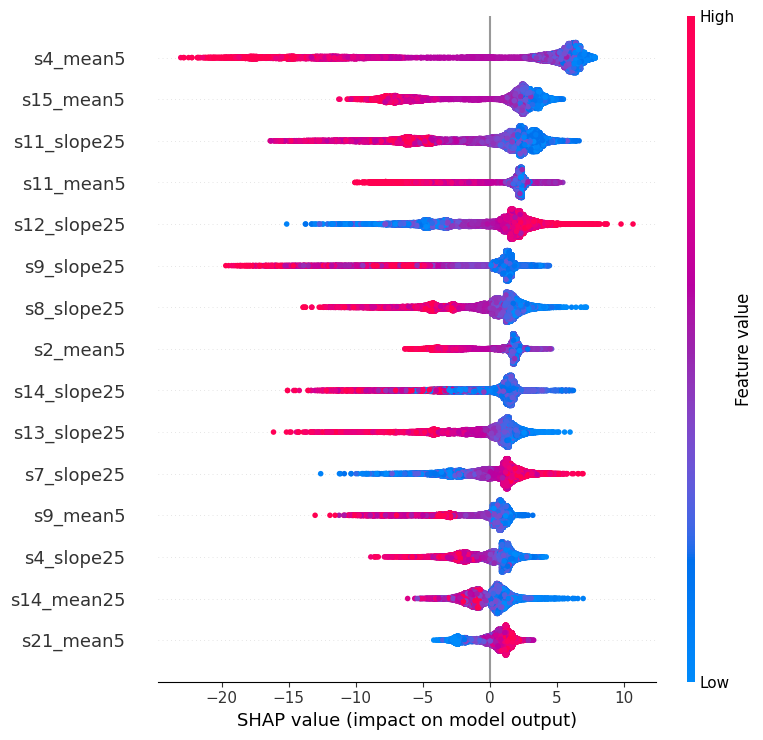

In [13]:
shap.summary_plot(shap_werte, X, max_display=15)

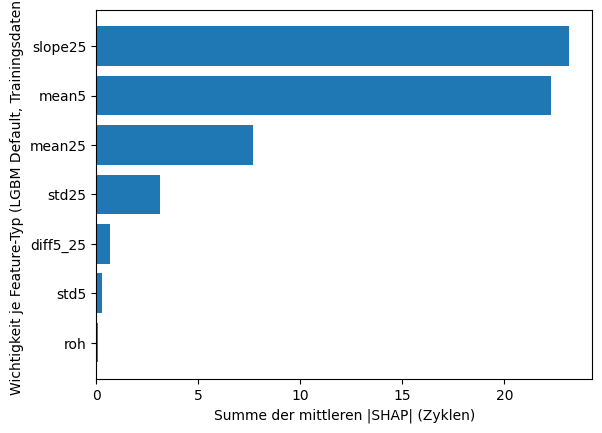

In [14]:
typ_werte = shap_df.groupby("typ")["wichtigkeit"].sum().sort_values(ascending=True)

plt.barh(typ_werte.index, typ_werte.values)
plt.xlabel("Summe der mittleren |SHAP| (Zyklen)")
plt.ylabel("Wichtigkeit je Feature-Typ (LGBM Default, Trainingsdaten)")
plt.show()

Hypothese SHAP Teil 2 (vorab, 30.10.)
s11_slope25: fallend (rechts unten), Spearman ρ ohne die künstlichen Nullen < −0,65 · flacher Bereich links (Sichtprüfung) · bei x = 0 genau 2.400 Zeilen, mittlerer SHAP > 0, Knick der Funktion bei x = 0,003
s9_slope25: gleiche Richtung wie s11, mehr senkrechte Streuung → |ρ| um mindestens 0,35 kleiner als bei s11 (bezogen auf den tatsächlichen s11-Wert)

In [15]:
n_nullen = (X["s11_slope25"]==0).sum()

In [16]:
spalte_s11_slope = X.columns.get_loc("s11_slope25")
shap_s11_slope = shap_werte[:,spalte_s11_slope]

In [17]:
s11_slope = X["s11_slope25"].to_numpy()
s11_slope_mask = s11_slope != 0

In [26]:
x_spear = s11_slope[s11_slope_mask]
y_spear = shap_s11_slope[s11_slope_mask]

print(len(y_spear))

spear_s11_slope = spearmanr(x_spear, y_spear).statistic
shap_s11_slope_x0 = shap_s11_slope[~s11_slope_mask].mean()

18231


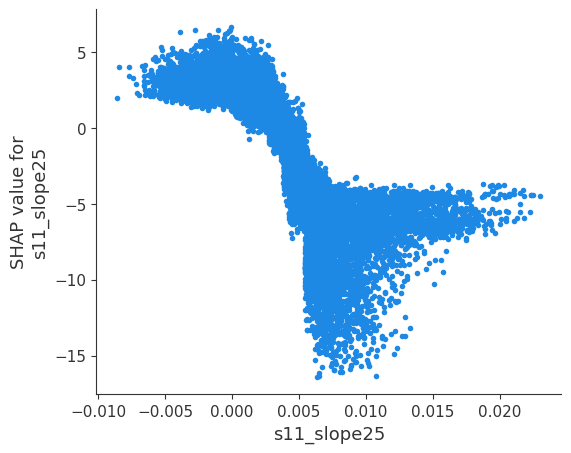

In [43]:
shap.dependence_plot("s11_slope25", shap_werte, X, interaction_index=None, show=False)
plt.savefig("../reports/figures/shap_dependence_plot_s11_slope.png")
plt.show()

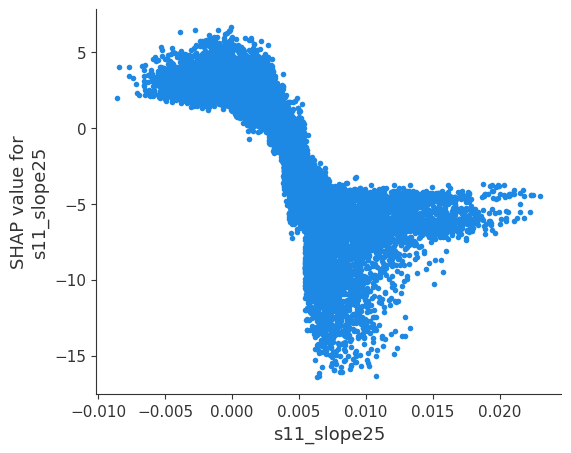

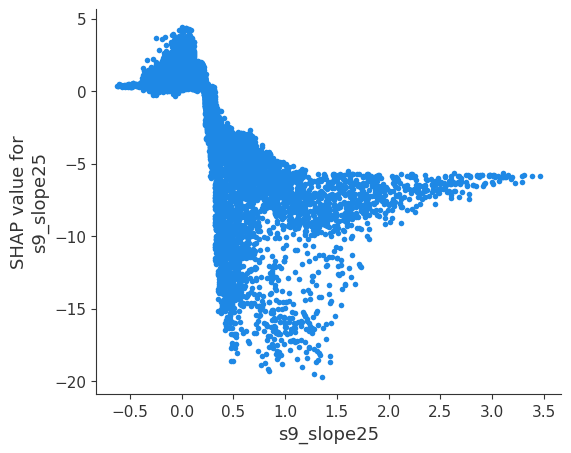

In [44]:
ergebnisse = []

for col in ["s11_slope25", "s9_slope25"]:
    n_nullen = (X[col] == 0).sum()
    spalte = X.columns.get_loc(col)
    shap_col = shap_werte[:, spalte]
    slope = X[col].to_numpy()
    col_mask = slope != 0

    x_spear = slope[col_mask]
    y_spear = shap_col[col_mask]

    rho = spearmanr(x_spear, y_spear).statistic
    mean_at_0 = shap_col[~col_mask].mean()

    ergebnisse.append({
        "feature": col,
        "n_nullen": n_nullen,
        "rho": rho,
        "shap bei 0":  mean_at_0,
    })

    shap.dependence_plot(col, shap_werte, X, interaction_index=None, show= False)
    plt.savefig(f"../reports/figures/shap_dependence_plot_{col}.png", dpi = 150, bbox_inches = "tight")
    plt.show()


tabelle = pd.DataFrame(ergebnisse)


In [45]:
tabelle

,feature,n_nullen,rho,shap bei 0
0,s11_slope25,2400,-0.912600,3.063493
1,s9_slope25,2400,-0.571067,1.474721


Abgleich von s9 Slope mit EDA auf Triebwerksebene:

Hypothese:
Bei höchstens 70 von 100 Triebwerken ist die `s9_slope25` im letzten Zyklus > 0.

In [73]:
last_units_s9_slope = df[df["RUL"]==0]["s9_slope25"]
assert len(last_units_s9_slope)==df["unit"].nunique(), "Falsche Länge"
np.count_nonzero(last_units_s9_slope > 0)

np.int64(68)

### SHAP Teil 2: Abhängigkeitsplots `s11_slope25` und `s9_slope25`

**Hypothese (vorab, 30.10.)**
- `s11_slope25`: fallend, Spearman ρ ohne die künstlichen Nullen < −0,65 · flacher Bereich links · Knick rechts von 0 bei ca. 0,003 · bei x = 0 genau 2.400 Zeilen (24 Zyklen × 100 Triebwerke wegen `min_periods=25`), mittlerer SHAP > 0
- `s9_slope25`: gleiche Richtung wie s11, mehr senkrechte Streuung → |ρ| um mindestens 0,35 kleiner als bei s11
- Triebwerks-Ebene: bei höchstens 70 von 100 Triebwerken ist `s9_slope25` im letzten Zyklus > 0

Spearman statt Pearson, weil eine monotone, aber nicht lineare Form erwartet wird (Bäume bilden Stufen, die Kappung erzeugt ein Plateau). Die Nullen bleiben draußen, weil sie Platzhalter für die ersten 24 Zyklen sind, keine Messungen.

**Ergebnis**

| Prüfung | Hypothese | Ergebnis | |
|---|---|---|---|
| s11: Zeilen bei x = 0 | 2.400 | 2.400 | ✓ |
| s11: ρ ohne Nullen | < −0,65 | −0,91 | ✓ |
| s11: mittlerer SHAP bei x = 0 | > 0 | +3,06 | ✓ |
| s11: flacher Bereich | links | oberes Plateau ca. +3 bis +5 | ✓ |
| s11: Knick | rechts von 0, ca. 0,003 | ca. 0,002 | ✓ |
| s9: \|ρ\| ohne Nullen | ≤ \|ρ_s11\| − 0,35 | -0,57 | ✗ |
| s9: Streuung | mehr als bei s11 | SHAP von ca. +5 bis −20 | ✓ |
| s9 im letzten Zyklus > 0 | ≤ 70 von 100 | 68 von 100 | ✓ |

→ **s11 bestätigt.** **s9 knapp widerlegt:** Die Vermutung zeigt in die richtige Richtung (|ρ| fällt von 0,91 auf 0,57, die Streuung ist deutlich größer). Die vorab festgelegte Schwelle ist aber verfehlt, der Abstand beträgt 0,3416 statt ≥ 0,35. Die Schwelle wird nicht nachträglich angepasst.

**Deutung**
- **Die Form ist eine Stufe mit zwei Plateaus**, kein linearer Verlauf. Das obere Plateau entsteht durch die Kappung bei 125: Alle Zeilen dort haben dasselbe Label, das Modell hat keinen Grund, sie zu unterscheiden. Das untere Plateau entsteht, weil die RUL nicht unter 0 fallen kann, rechts nur wenige Punkte liegen und Bäume nicht extrapolieren.
- **Der Knick liegt rechts von 0:** s11 steigt schon leicht, bevor das Modell abzieht. Frühe Degradation wird durch die Kappung als „gesund“ gelabelt. Das ist ein Argument für die Kappungs-Sensitivität (115/125/135).
- **Die x-Achsen sind nicht vergleichbar:** s9 misst eine Drehzahl, die Steigungen sind rund 100× größer als bei s11.
- **s9 ist ein einseitiges Signal:** Bei 32 von 100 Triebwerken fällt s9 am Lebensende. Damit ist das EDA-Urteil „uneindeutig“ auf Triebwerks-Ebene beziffert. Ein flaches s9 bringt kaum Bonus (oberes Plateau nur ca. 0 bis +2 statt +3 bis +5 bei s11). Ein steigender s9 ist ein Alarm, ein fallender s9 sagt nichts. Das passt zu SHAP Teil 1, wo s9 sich wie ein steigender Sensor verhielt.
  - *Vermutung, ungeprüft:* Die dünne Linie links (x ≈ −0,6 bis −0,2, SHAP ≈ +0,3) sind die späten Zeilen genau dieser 32 Triebwerke. Das Modell ignoriert s9 dort.

**Offen (Vermutungen, ungeprüft)**
- **Trichter nach der Stufe:** Bei gleichem x liegen die SHAP-Werte zwischen ca. −4 und −16 (s11) bzw. −20 (s9). Das ist Wechselwirkung. Vermutung: Die Steigung teilt sich den Kredit mit `mean5` und bekommt dort großes Minus, wo `mean5` den Verschleiß noch nicht zeigt. Prüfung: `interaction_index="s11_mean5"`.
- **Spitze bei x = 0:** s9 reicht dort bis ca. +4, s11 bis ca. +6,5. Vermutung: Das Modell hat den Platzhalter 0 als Altersmarker gelernt („erste 24 Zyklen = jung“). Das ist kein Leakage, weil die Zykluszahl im Betrieb bekannt ist, aber ein Artefakt der Feature-Konstruktion. Prüfung: mittlerer SHAP bei exakt 0 gegen echte Steigungen nahe 0 (z. B. s9 mit |x| < 0,05 und x ≠ 0). Für den Testlauf irrelevant, wenn das kürzeste Testtriebwerk mindestens 25 Zyklen hat.

Plots: `reports/figures/shap_dependence_plot_s11_slope25.png`, `reports/figures/shap_dependence_plot_s9_slope25.png`